# Industry Classification – Practical 1

**Natalia Piegat** — *25-717-034*  
**Fraia Pérez-Rayón** — *25-744-087*

In [1]:
import numpy as np
import pandas as pd
import ast
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
import seaborn as sns

# Loading Data

In [2]:
df_company_industry = pd.read_pickle(r"C:\Users\fraia\OneDrive - Universität Zürich UZH\Sem I. Foundations of Data Science\GP\data\data\df_train.pkl")

df_train, df_val = train_test_split(df_company_industry, test_size= 0.1, random_state=42)

In [3]:
X_train = df_train.business_description_embedding.apply(ast.literal_eval).tolist()
X_train = np.array(X_train)

X_val = df_val.business_description_embedding.apply(ast.literal_eval).tolist()
X_val = np.array(X_val)

In [4]:
df_train.head(3)

,id,industry,business_description_embedding
31138,34170,Financial Services,"[0.019633012,0.009427597,0.006240986,0.0177257..."
15120,16504,Technology Hardware & Equipment,"[0.026561439,-0.049749356,-0.006847293,-0.0088..."
23693,25893,Consumer Durables & Apparel,"[0.0115894,-0.035240766,-0.029952582,0.0226988..."


# Transforming Data (Label Encoding)

### Tasks:
- Use the scikit-learn label encoder to encode the industry names
- Check if all classes contained in the validation set are also in the training set

#

In [5]:
# Fit the label encoder to the classes (industry names)

set_train = set(df_train["industry"])
set_val = set(df_val["industry"])

is_subset = set_val.issubset(set_train)
    
print(f"All classes in training set are in the validation set: {is_subset}")

num_cls = len(set_train)

print(f"The total number of classes is: {num_cls}")

All classes in training set are in the validation set: True
The total number of classes is: 25


In [6]:
le = LabelEncoder()

le.fit(df_train["industry"])

y_train = le.transform(df_train["industry"]) 
y_val =  le.transform(df_val["industry"])

In [7]:
label_map = {idx: label for idx, label in enumerate(le.classes_)}
label_map

{0: 'Automobiles & Components',
 1: 'Banks',
 2: 'Capital Goods',
 3: 'Commercial & Professional Services',
 4: 'Consumer Discretionary Distribution & Retail',
 5: 'Consumer Durables & Apparel',
 6: 'Consumer Services',
 7: 'Consumer Staples Distribution & Retail',
 8: 'Energy',
 9: 'Equity Real Estate Investment Trusts (REITs)',
 10: 'Financial Services',
 11: 'Food, Beverage & Tobacco',
 12: 'Health Care Equipment & Services',
 13: 'Household & Personal Products',
 14: 'Insurance',
 15: 'Materials',
 16: 'Media & Entertainment',
 17: 'Pharmaceuticals, Biotechnology & Life Sciences',
 18: 'Real Estate Management & Development',
 19: 'Semiconductors & Semiconductor Equipment',
 20: 'Software & Services',
 21: 'Technology Hardware & Equipment',
 22: 'Telecommunication Services',
 23: 'Transportation',
 24: 'Utilities'}

# Visualize the data

### Tasks:
- Are certain classes over- or under represented? Either produce a table or a plot to show this.
- Inspect whether there is signal in the business description embeddings:
    - Perform a PCA to project data into 2 dimensions
    - Plot projected data in Scatterplot and color based on classes
    - Provide a description of what you see and judge whether there is signal in the data that allows industry classification

Important: Ensure that your plots have proper axis descriptions and titles. Style the plots so that differences in class distributions are visible (e.g. scatter size, transparency, color, etc.)

### Class distribution

C:\Users\fraia\AppData\Local\Temp\ipykernel_10964\949444105.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=counts, x="Num_Companies", y="Industry", palette="husl")


Text(0.5, 0, 'Count')

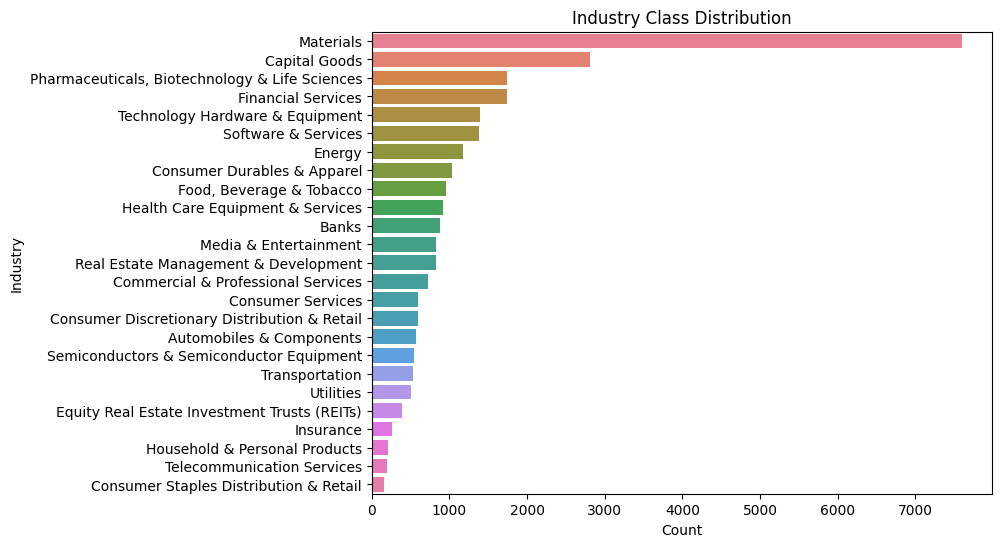

In [8]:
# Plot the class distribution or provide a table that shows how many times each class (industry) appears
# Describe your findings
counts = df_train["industry"].value_counts().reset_index()
counts.columns = ["Industry", "Num_Companies"]

plt.figure(figsize=(8, 6))
ax = sns.barplot(data=counts, x="Num_Companies", y="Industry", palette="husl")

plt.title('Industry Class Distribution')
plt.ylabel('Industry')
plt.xlabel('Count')

### PCA - Dimensionality reduction and visualization

Text(0, 0.5, 'Principal Component 2')

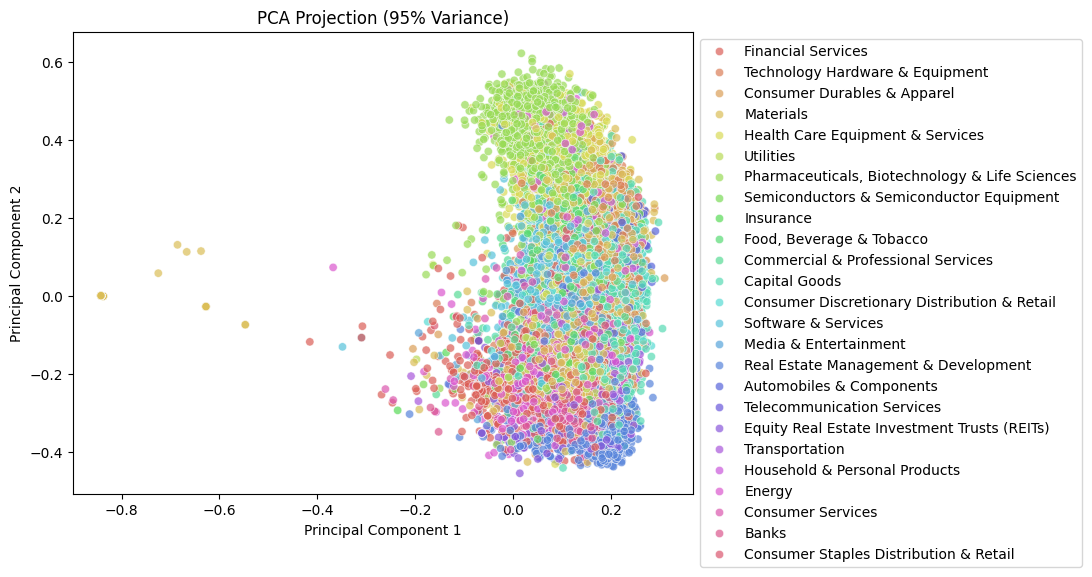

In [9]:
# Perform a PCA and plot the projected data. Color the scatter plot based on the classes
# Analyse what you see
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(X_train)

pca_df = pd.DataFrame(X_reduced, columns=[f"PC{i+1}" for i in range(X_reduced.shape[1])])
pca_df['industry'] = le.inverse_transform(y_train)

# Plot
plt.figure(figsize=(8, 6))
sc = sns.scatterplot(
    x='PC1',
    y='PC2',
    hue='industry',
    data= pca_df,
    palette='hls',
    alpha=0.7
)
sc.legend(bbox_to_anchor= (1,1))
plt.title('PCA Projection (95% Variance)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')


### Interpretation

In the latter plot, we can observe the PCA projection with the first two components (on the x- and y-axis) capturing 95% of the variance in the data.  
We can notice several clusters of companies belonging to the same industry; nevertheless, they are strongly overlapping, indicating high feature similarity across industries.  
There are some industries, such as **"Pharmaceuticals, Biotechnology & Life Sciences,"** where the signal is strong, which may allow for correct industry classification.  
Nevertheless, the overlapping condition implies that correct classification will not be an easy task.


# Fitting and comparing Classifier Models

### Tasks:
- Split the data into train and validation data
- Encode the industry labels using LabelEncoder (scikit-learn)
- Fit a LogisticRegression and a kNN-classifier
- Compare the model performance of both models:
    - Compute Accuracy and F1 score
        - Interpret the scores: Explain how they are computed and judge if your model performs well
        - Analyze the classification errors: 
            - Do the errors correlate with how well classes are represented?
            - Which industries does the model identify well and which seem to be similar?
    - Plot a confusion matrix for both models (combine scikit-learn confusion matrix and seaborn heatmap plot)
    - Do both models misclassify the same examples?

Import: Use proper axis labels for the plots! 

In [10]:
# Logistic Regression
log_reg = LogisticRegression()
log_reg_1 = log_reg.fit(X_reduced, y_train)

In [11]:
#Knn Classifier
knn_clf = KNeighborsClassifier()
knn_clf_1 = knn_clf.fit(X_reduced, y_train)

In [12]:
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, classification_report

#PCA reduction validation set
X_val_reduced = pca.transform(X_val)
y_pred_lg = log_reg_1.predict(X_val_reduced)
y_pred_knn = knn_clf_1.predict(X_val_reduced)
y_true = y_val

print("\nLogistic Regression")
precision_lg = precision_score(y_true, y_pred_lg, average="weighted")
recall_lg = recall_score(y_true, y_pred_lg, average="weighted")
f1_lg = f1_score(y_true, y_pred_lg, average="weighted")
accuracy_lg = accuracy_score(y_true, y_pred_lg)

print(f"Precision: {precision_lg:.3f}")
print(f"Recall:    {recall_lg:.3f}")
print(f"F1 Score:  {f1_lg:.3f}")
print(f"Accuracy: {accuracy_lg:.3f}")

print("\nKnn Classifier")
precision_knn = precision_score(y_true, y_pred_knn, average="weighted")
recall_knn = recall_score(y_true, y_pred_knn, average="weighted")
f1_knn = f1_score(y_true, y_pred_knn, average="weighted")
accuracy_knn = accuracy_score(y_true, y_pred_knn)

print(f"Precision: {precision_knn:.3f}")
print(f"Recall:    {recall_knn:.3f}")
print(f"F1 Score:  {f1_knn:.3f}")
print(f"Accuracy: {accuracy_knn:.3f}")



Logistic Regression
Precision: 0.766
Recall:    0.770
F1 Score:  0.764
Accuracy: 0.770

Knn Classifier
Precision: 0.751
Recall:    0.753
F1 Score:  0.749
Accuracy: 0.753


In [13]:
# Comprehensive report Logistic Regression
print("\nClassification Report Logistic Regression:")
print(classification_report(
    y_true,
    y_pred_lg,
    target_names= le.classes_
))


Classification Report Logistic Regression:
                                                precision    recall  f1-score   support

                      Automobiles & Components       0.67      0.64      0.65        53
                                         Banks       0.99      0.92      0.95        74
                                 Capital Goods       0.65      0.75      0.70       322
            Commercial & Professional Services       0.53      0.32      0.40        78
  Consumer Discretionary Distribution & Retail       0.61      0.54      0.57        67
                   Consumer Durables & Apparel       0.69      0.57      0.63       127
                             Consumer Services       0.74      0.68      0.71        81
        Consumer Staples Distribution & Retail       0.25      0.05      0.08        20
                                        Energy       0.83      0.55      0.66       152
  Equity Real Estate Investment Trusts (REITs)       0.84      0.82      0.

In [14]:
# Comprehensive report Knn Classifier
print("\nClassification Report KNN Classifier:")
print(classification_report(
    y_true,
    y_pred_knn,
    target_names= le.classes_
))


Classification Report KNN Classifier:
                                                precision    recall  f1-score   support

                      Automobiles & Components       0.71      0.77      0.74        53
                                         Banks       0.80      0.96      0.87        74
                                 Capital Goods       0.62      0.74      0.68       322
            Commercial & Professional Services       0.48      0.32      0.38        78
  Consumer Discretionary Distribution & Retail       0.47      0.57      0.51        67
                   Consumer Durables & Apparel       0.63      0.55      0.59       127
                             Consumer Services       0.74      0.68      0.71        81
        Consumer Staples Distribution & Retail       0.36      0.25      0.29        20
                                        Energy       0.77      0.58      0.66       152
  Equity Real Estate Investment Trusts (REITs)       0.76      0.76      0.76   

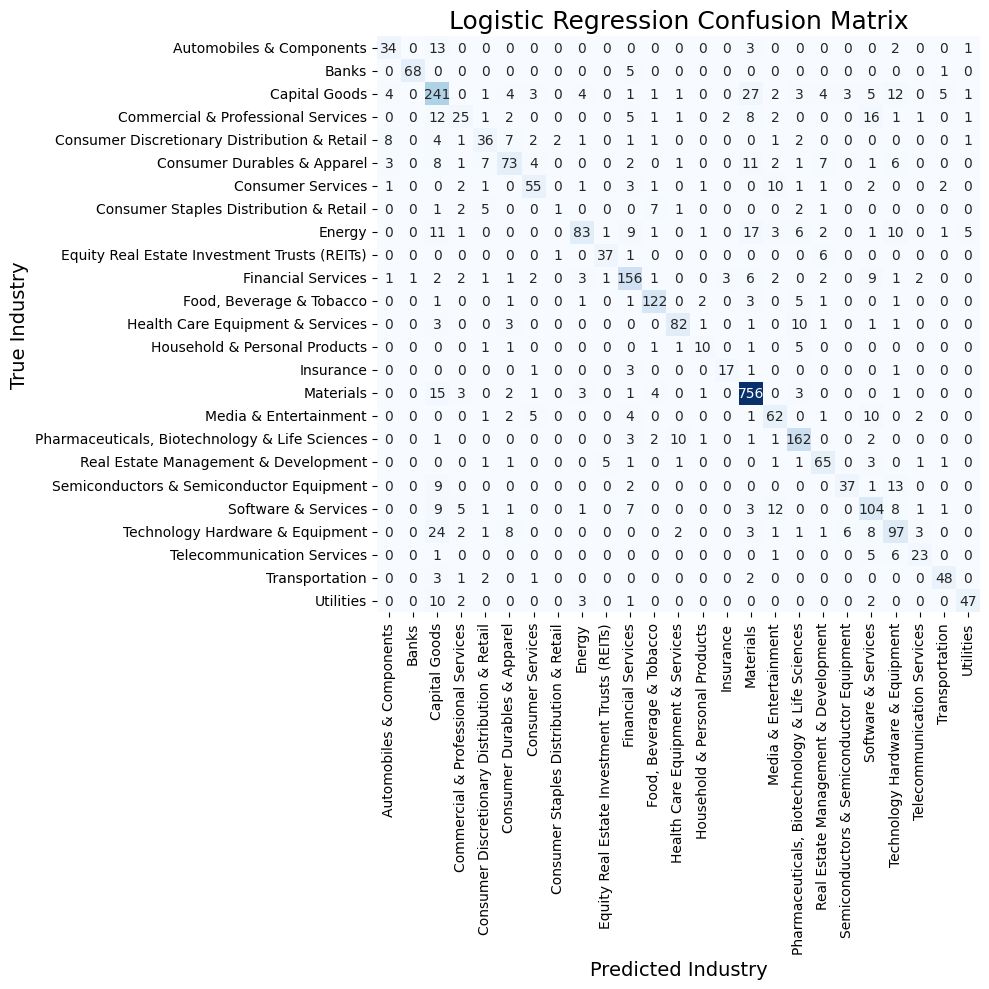

In [15]:
target_names = le.classes_

cm1 = confusion_matrix(y_true, y_pred_lg)
cm2 = confusion_matrix(y_true, y_pred_knn)

plt.figure(figsize=(10, 10))

sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', cbar=False, yticklabels=target_names, xticklabels=target_names)
plt.title('Logistic Regression Confusion Matrix', fontsize=18)
plt.xlabel('Predicted Industry', fontsize=14)
plt.ylabel('True Industry', fontsize=14)

plt.tight_layout()
plt.show()


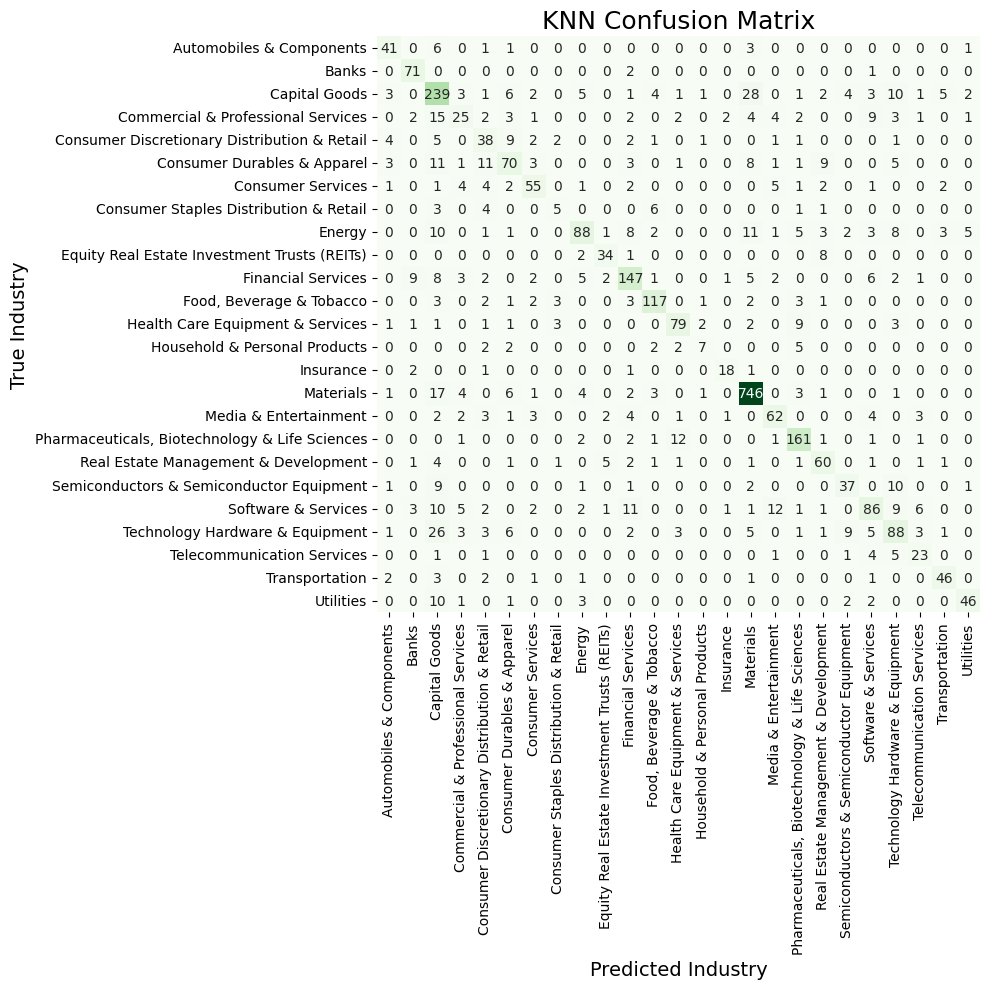

In [16]:
plt.figure(figsize=(10, 10))

sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', cbar=False, yticklabels=target_names, xticklabels = target_names)
plt.title('KNN Confusion Matrix', fontsize=18)
plt.xlabel('Predicted Industry', fontsize=14)
plt.ylabel('True Industry', fontsize=14)

plt.tight_layout()
plt.show()

### Conclusions

- **Score Interpretation**  
  Accuracy measures how many samples were classified correctly out of the total results. Moreover, the F1 Score calculates the harmonic mean between precision and recall, ensuring a balance between these two measures. Compared to accuracy, the F1 Score is a better measure for misclassified cases. Considering the high dimensionality of the data and the fact that we only have one variable (**embeddings of business description**), the model classifies fairly well.

- **Analysis of Classification Errors**  
  The errors partially correlate with how well classes are represented, larger classes despite having moderate f1 scores, contribute the most to the total accuracy given that they appear more frequently and thus are correctly predicted more often.  

  We noticed that some industries which are related to each other share lower scores, indicating that they might have similar descriptions causing them to be mixed up during classification. For instance, technology related industries such as **Semiconductors**, **Software**, **Tech Hardware** and **Telecommunication Services**. Another example would be in the consumer sector including industries such as **Consumer Discretionary Distribution and Retail**, **Consumer Durables and Apparel**, **Consumer Staples Distribution & Retail** and **Household and Personal Products**.

  **Transportation** and **Pharmaceuticals, Biotechnology & Life Sciences** might have more technical descriptions, leading to higher scores as they are more unique within the dataset.

  Lastly, both models tend to misclassify similarly (highly represented classes are better classified than lower represented ones). Nevertheless, misclassifications aren't identical, meaning that an ensemble model of the two classifiers, could potentially improve predictions. 


# Optional: Confidence Weighted Prediction

## Deliverables:

- Provide a notebook with the implementation and training of a industry classifier model
- The model shall output the industry classification and its confidence as a tuple of vectors $(\hat{y}_{pred}, \hat{y}_{confidence})$
- The confidence score must be between 0 and 1, $\hat{y}_{confidence} [i] \in [0,1]$
- Your model will be evaluated on a private test set
- The designing the confidence score is your task. You may use p-values, a voting mechanism of multiple models, or other techniques
- Another option is to add more features, e.g. financial data, to X

In [37]:
import numpy as np
import pandas as pd
import ast

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.preprocessing import LabelEncoder
from sklearn.decomposition import PCA
import seaborn as sns
from scipy import stats
from sklearn.pipeline import Pipeline

In [18]:
df_company_financials =  pd.read_pickle(r"C:\Users\fraia\OneDrive - Universität Zürich UZH\Sem I. Foundations of Data Science\GP\data\data\df_financials_train.pkl")

In [38]:
df = df_company_industry.merge(df_company_financials, on="id")

df.isnull().sum() 

id                                    0
industry                              0
business_description_embedding        0
country_code                          0
net_profit_margin                  1111
ebitda_margin                     19279
asset_turnover                     1363
dtype: int64

95s Percentile:  1.3826873281018173


Text(0.5, 0, 'Asset Turnover')

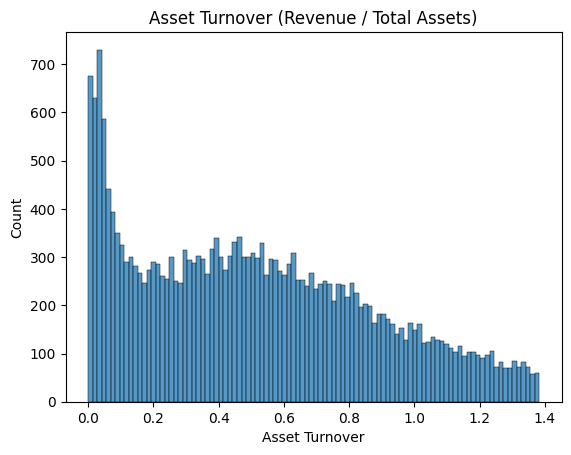

In [71]:
percentile_95 = df["asset_turnover"].quantile(0.95)

print("95s Percentile: ", percentile_95)
df = df[df.asset_turnover < percentile_95]
df = df[df.asset_turnover > 0]

sns.histplot(df.asset_turnover, bins=100)
plt.title("Asset Turnover (Revenue / Total Assets)")
plt.xlabel("Asset Turnover")

In [ ]:

df_margins = df_company_industry.merge(df_company_financials, on="id")
df_margins = df_margins[df_margins.net_profit_margin < 0.9]
df_margins = df_margins[(~df_margins.net_profit_margin.isna()) & (df_margins.net_profit_margin >= 0)]

# handling outliers
df_margins = df_margins[(df_margins.net_profit_margin > 0) & (df_margins.net_profit_margin< 0.55)]
SHIFT =  0.008
df_margins["log_margin"] = np.log(df_margins["net_profit_margin"].values + SHIFT)

95s Percentile:  1.8018310430448619


Text(0.5, 1.0, 'Distribution of log-profit margins')

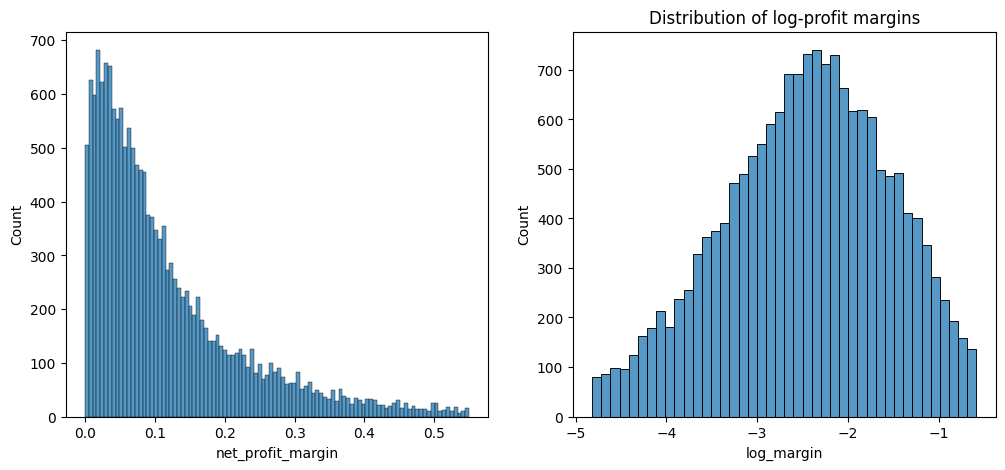

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df_margins.net_profit_margin, bins=100, ax=axes[0])
plt.title("Net Profit Margins")

sns.histplot(df_margins.log_margin, ax=axes[1])
plt.title("Distribution of log-profit margins")

In [75]:
df_ind_stats = df.groupby("industry")["asset_turnover"].agg(["count", "mean", "std"], ).reset_index()
df_ind_stats = df_ind_stats[~df_ind_stats["std"].isna()]
df_ind_stats.to_csv("industry_rev_per_asset.csv")
df_ind_stats

df_ind_stats = df.groupby("industry")["asset_turnover"].agg(["count", "mean", "std"]).reset_index()
df_ind_stats = df_ind_stats[~df_ind_stats["std"].isna()]

In [76]:
columns = ["id","industry","business_description_embedding", "asset_turnover", "country_code", "log_margin", "net_profit_margin"]
df = df_margins[columns]

In [77]:
df.isnull().sum()

id                                 0
industry                           0
business_description_embedding     0
asset_turnover                    74
country_code                       0
log_margin                         0
net_profit_margin                  0
dtype: int64

In [23]:
df.dropna(inplace=True)

C:\Users\fraia\AppData\Local\Temp\ipykernel_10964\1379821321.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.dropna(inplace=True)


In [24]:
df_train, df_val = train_test_split(df, test_size= 0.1, random_state=42)

In [25]:
X_train_embed = df_train.business_description_embedding.apply(ast.literal_eval).tolist()
X_val_embed = df_val.business_description_embedding.apply(ast.literal_eval).tolist()
X_train_embed = np.array(X_train_embed)
X_val_embed = np.array(X_val_embed)

num_vars = ["log_margin", "net_profit_margin"]
X_train_num = df_train[num_vars].to_numpy()
X_val_num = df_val[num_vars].to_numpy()

#Putting it all together
X_train = np.concatenate([X_train_embed, X_train_num], axis=1)
X_val = np.concatenate([X_val_embed, X_val_num], axis=1)

print(X_train.shape, X_val.shape)

(15095, 770) (1678, 770)


In [26]:
le = LabelEncoder()
y_train = le.fit_transform(df_train['industry']) 
y_val =  le.transform(df_val['industry']) 

In [27]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [28]:
clf_lg = LogisticRegression(max_iter=2000, solver='lbfgs', class_weight='balanced')

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_lg = GridSearchCV(
    estimator=clf_lg,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1,  # Uses all CPU cores
    verbose=1
)

grid_lg.fit(X_train, y_train)

print("Best params (LG):", grid_lg.best_params_)
print("Best CV F1 (LG):", grid_lg.best_score_)

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best params (LG): {'C': 10}
Best CV F1 (LG): 0.7343192289579099


In [29]:
knn_clf_2 = KNeighborsClassifier()

param_grid_knn = {
    'n_neighbors': [3, 5, 7, 9, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid_knn = GridSearchCV(
    knn_clf_2,
    param_grid_knn,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(X_train, y_train)

print("Best params (kNN):", grid_knn.best_params_)
print("Best CV F1 (kNN):", grid_knn.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best params (kNN): {'metric': 'manhattan', 'n_neighbors': 9, 'weights': 'distance'}
Best CV F1 (kNN): 0.735244879663629


In [30]:
clf_rf = RandomForestClassifier(random_state=42)

param_grid_rf = {
    'n_estimators': [200, 400, 600],
    'max_depth': [10, 20, 40, None],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced']
}

grid_rf = GridSearchCV(
    clf_rf,
    param_grid_rf,
    scoring='f1_macro',
    cv=skf,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

print("Best params (RF):", grid_rf.best_params_)
print("Best CV F1 (RF):", grid_rf.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best params (RF): {'class_weight': 'balanced', 'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 400}
Best CV F1 (RF): 0.721939252112642


In [97]:
voting_clf = VotingClassifier(
    estimators=[
        ('clf_knn', grid_knn.best_estimator_), 
        ('clf_knn2', grid_knn.best_estimator_),
        ('clf_lr', grid_lg.best_estimator_),
        ('clf_rf', grid_lg.best_estimator_) 
    ],
    voting='soft',  
    weights=[1,1,2,1]
)

voting_clf.fit(X_train, y_train)

y_pred = voting_clf.predict(X_val)
probabilities = voting_clf.predict_proba(X_val)

precision = precision_score(y_val, y_pred, average="weighted")
recall = recall_score(y_val, y_pred, average="weighted")
f1 = f1_score(y_val, y_pred, average="weighted")

confidences = np.max(probabilities, axis=1)
results = (y_pred, confidences) #tuple of vectors

# Model Evlauation - (Confidence Weighted F1)

In [98]:
def multiclass_confidence_weighted_f1(y_true, y_pred, confidence):
    classes = np.unique(y_true)
    f1_list = []
    
    for cls in classes:
        weigthed_tp = np.sum(confidence * (y_pred == cls) * (y_true == cls))
        weigthed_fp = np.sum(confidence * (y_pred == cls) * (y_true != cls))
        weigthed_fn = np.sum(confidence * (y_pred != cls) * (y_true == cls))
        
        precision = weigthed_tp / (weigthed_tp + weigthed_fp) if (weigthed_tp + weigthed_fp) > 0 else 0
        recall = weigthed_tp / (weigthed_tp + weigthed_fn) if (weigthed_tp + weigthed_fn) > 0 else 0
        f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
        f1_list.append(f1)
    
    class_counts = np.array([np.sum(y_true == cls) for cls in classes])
    weighted_f1 = np.sum(f1_list * class_counts) / np.sum(class_counts) #an average of all the classes 
    
    return weighted_f1


f1_conf_weighted = multiclass_confidence_weighted_f1(y_val, y_pred, confidences)


precision = precision_score(y_val, y_pred, average="weighted")
recall = recall_score(y_val, y_pred, average="weighted")
f1 = f1_score(y_val, y_pred, average="weighted")

print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1 Score:  {f1:.3f}")
print(f"Confidence-weighted F1: {f1_conf_weighted:.3f}")

Precision: 0.794
Recall:    0.791
F1 Score:  0.790
Confidence-weighted F1: 0.828


In [99]:
y_pred_industry = le.inverse_transform(y_pred)
y_true_industry = le.inverse_transform(y_val)

df_results = pd.DataFrame({
    'True Industry': y_true_industry,
    'Predicted Industry': y_pred_industry,
    'Confidence': confidences
})

df_results

,True Industry,Predicted Industry,Confidence
0,Materials,Materials,0.516757
1,Consumer Durables & Apparel,Technology Hardware & Equipment,0.507239
2,Utilities,Utilities,0.927764
3,Utilities,Utilities,0.995440
4,Technology Hardware & Equipment,Capital Goods,0.535989
...,...,...,...
1673,Utilities,Utilities,0.996393
1674,Energy,Capital Goods,0.410063
1675,Capital Goods,Capital Goods,0.411827
1676,Materials,Materials,0.341622


In [100]:
# Top 10 misclassified industries 
most_unclassified = []

for idx, row in df_results.iterrows():
    if row["True Industry"] != row["Predicted Industry"] and row["Confidence"] < 0.5:
        most_unclassified.append(row)
most_unclassified = pd.DataFrame(most_unclassified)

class_counts = df_results["True Industry"].value_counts()

unclassified_counts = most_unclassified["True Industry"].value_counts()

unclassified_ratio = (unclassified_counts / class_counts)

top10_true_industry = unclassified_ratio.sort_values(ascending= False).head(10)

top10_true_industry

True Industry
Commercial & Professional Services              0.307692
Consumer Discretionary Distribution & Retail    0.190476
Capital Goods                                   0.173913
Energy                                          0.150000
Automobiles & Components                        0.139535
Software & Services                             0.132075
Technology Hardware & Equipment                 0.112245
Media & Entertainment                           0.107143
Financial Services                              0.092593
Consumer Staples Distribution & Retail          0.090909
Name: count, dtype: float64

In [101]:
from sklearn.metrics import classification_report
print("\nClassification Report Voting Classifier:")
print(classification_report(
    y_val,
    y_pred,
    target_names= le.classes_
))


Classification Report Voting Classifier:
                                                precision    recall  f1-score   support

                      Automobiles & Components       0.58      0.77      0.66        43
                                         Banks       0.93      0.94      0.93        93
                                 Capital Goods       0.74      0.62      0.68       207
            Commercial & Professional Services       0.39      0.38      0.39        39
  Consumer Discretionary Distribution & Retail       0.71      0.48      0.57        42
                   Consumer Durables & Apparel       0.73      0.69      0.71        70
                             Consumer Services       0.69      0.85      0.76        39
        Consumer Staples Distribution & Retail       0.50      0.55      0.52        11
                                        Energy       0.68      0.57      0.62        60
  Equity Real Estate Investment Trusts (REITs)       0.94      0.85      0.89

Classes that are most frequently misclassified and have low prediction confidences generally show lower F1 scores.

In [102]:
def test_company_classification(rev_per_asset, claimed_industry, df_stats):
    """Test if a company's margin is consistent with its claimed industry"""
    industry_row = df_stats[df_stats['industry'] == claimed_industry]
    
    if industry_row.empty:
        return None, (claimed_industry, 0.0)
    
    industry_mean = industry_row['mean'].values[0]
    industry_std = industry_row['std'].values[0]
    
    z_score = (rev_per_asset - industry_mean) / industry_std
    percentile = stats.norm.cdf(z_score)
    p_value = 2 * min(percentile, 1 - percentile)
    
    confidence = max(0.0, min(1.0, 1 - p_value))
    
    details = {
        'industry': claimed_industry,
        'industry_mean': industry_mean,
        'industry_std': industry_std,
        'rev_per_asset': rev_per_asset,
        'z_score': z_score,
        'percentile': percentile * 100,
        'p_value': p_value,
        'deviation_pct': ((rev_per_asset / industry_mean) - 1) * 100
    }
    
    return details, (claimed_industry, confidence)

results_list = []
for i, pred in enumerate(y_pred_industry):
    rev = df_val.iloc[i]['asset_turnover']
    details, tup = test_company_classification(rev, pred, df_ind_stats)
    results_list.append((details, tup))


print("🔍 Company Classification Tests:\n")
for details, (industry, confidence) in results_list:
    if details is None:
        print(f"No stats available for industry '{industry}'.\n")
        continue

    print(f"Company with {details['rev_per_asset']:.3f} Asset Turnover supposed to be in {details['industry']}:")
    print(f"  Industry mean: {details['industry_mean']:.3f} (σ = {details['industry_std']:.3f})")
    print(f"  Z-score: {details['z_score']:.3f}")
    print(f"  P-value: {details['p_value']:.6f}")
    
    if details['p_value'] < 0.01:
        print("🚨 Unlikely: Very likely to be misclassified!\n")
    elif details['p_value'] < 0.05:
        print("⚠️ Suspicious: Likely misclassified\n")
    elif details['p_value'] < 0.15:
        print("🤔 Should be investigated: Possibly misclassified\n")
    else:
        print("✅ Plausible: Classification seems reasonable\n")

🔍 Company Classification Tests:

Company with 1.191 Asset Turnover supposed to be in Materials:
  Industry mean: 0.914 (σ = 11.078)
  Z-score: 0.025
  P-value: 0.979999
✅ Plausible: Classification seems reasonable

Company with 0.284 Asset Turnover supposed to be in Technology Hardware & Equipment:
  Industry mean: 0.859 (σ = 0.674)
  Z-score: -0.853
  P-value: 0.393532
✅ Plausible: Classification seems reasonable

Company with 0.119 Asset Turnover supposed to be in Utilities:
  Industry mean: 2.137 (σ = 33.321)
  Z-score: -0.061
  P-value: 0.951703
✅ Plausible: Classification seems reasonable

Company with 0.116 Asset Turnover supposed to be in Utilities:
  Industry mean: 2.137 (σ = 33.321)
  Z-score: -0.061
  P-value: 0.951628
✅ Plausible: Classification seems reasonable

Company with 0.635 Asset Turnover supposed to be in Capital Goods:
  Industry mean: 0.978 (σ = 4.663)
  Z-score: -0.073
  P-value: 0.941436
✅ Plausible: Classification seems reasonable

Company with 1.232 Asset Turn